In [1]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the Breast Cancer dataset
cancer = load_breast_cancer()

# Convert dataset into a DataFrame
data = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Add target column
data["target"] = cancer.target

# Display first 5 rows
print("First 5 rows of the dataset:")
display(data.head())


First 5 rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:

# Check dataset size
print("Dataset Shape:", data.shape)

# Check target classes
print("\nTarget Classes:")
print(cancer.target_names)

# Count samples in each class
print("\nClass Distribution:")
print(data["target"].value_counts())

# Check missing values
print("\nTotal Missing Values:")
print(data.isnull().sum().sum())


Dataset Shape: (569, 31)

Target Classes:
['malignant' 'benign']

Class Distribution:
target
1    357
0    212
Name: count, dtype: int64

Total Missing Values:
0


In [4]:

# Separate input features and target

X = data.drop("target", axis=1)
y = data["target"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)


Input Features Shape: (569, 30)
Target Shape: (569,)


In [5]:

# Split dataset into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


Training Samples: 455
Testing Samples: 114


In [6]:

# Feature Scaling

scaler = StandardScaler()

# Learn scaling values from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)


Feature Scaling Completed!
Scaled Training Shape: (455, 30)
Scaled Testing Shape: (114, 30)


In [7]:

# Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Predict using testing data
lr_pred = lr_model.predict(X_test_scaled)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy)


Logistic Regression Accuracy: 0.9824561403508771


In [8]:

# Decision Tree Classifier

dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Predict using testing data
dt_pred = dt_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)


Decision Tree Accuracy: 0.9122807017543859


In [9]:

# K-Nearest Neighbors Classifier

knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Predict using testing data
knn_pred = knn_model.predict(X_test_scaled)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", knn_accuracy)


KNN Accuracy: 0.956140350877193


In [10]:

# Compare Base ML Models

base_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        knn_accuracy
    ]
})

print("Base Machine Learning Model Comparison:")
display(base_results)


Base Machine Learning Model Comparison:


,Model,Accuracy
0,Logistic Regression,0.982456
1,Decision Tree,0.912281
2,KNN,0.956140


In [11]:

# Import Pipeline
from sklearn.pipeline import make_pipeline

# Define base classifiers
base_models = [
    ("lr", make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )),
    ("dt", DecisionTreeClassifier(random_state=42)),
    ("knn", make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ))
]

# Create Stacking Ensemble
stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

print("Stacking Ensemble Created Successfully!")


Stacking Ensemble Created Successfully!


In [12]:

# Train Stacking Ensemble

stacking_model.fit(X_train, y_train)

print("Stacking Ensemble Training Completed!")


Stacking Ensemble Training Completed!


In [13]:

# Predict using Stacking Ensemble
stacking_pred = stacking_model.predict(X_test)

# Calculate Accuracy
stacking_accuracy = accuracy_score(y_test, stacking_pred)

print("Stacking Ensemble Accuracy:", stacking_accuracy)
print("Stacking Ensemble Accuracy (%):",
      round(stacking_accuracy * 100, 2))


Stacking Ensemble Accuracy: 0.9824561403508771
Stacking Ensemble Accuracy (%): 98.25


In [14]:

# Stacking Ensemble Performance Metrics

print("Stacking Ensemble Performance:")

print("Accuracy:",
      accuracy_score(y_test, stacking_pred))

print("Precision:",
      precision_score(y_test, stacking_pred, average="macro"))

print("Recall:",
      recall_score(y_test, stacking_pred, average="macro"))

print("F1-score:",
      f1_score(y_test, stacking_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    stacking_pred,
    target_names=["Malignant", "Benign"]
))


Stacking Ensemble Performance:
Accuracy: 0.9824561403508771
Precision: 0.9864864864864865
Recall: 0.9761904761904762
F1-score: 0.9809555629802873

Classification Report:
              precision    recall  f1-score   support

   Malignant       1.00      0.95      0.98        42
      Benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [15]:

# Create AdaBoost Ensemble

adaboost_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

print("AdaBoost Model Created Successfully!")


AdaBoost Model Created Successfully!


In [16]:

# Train AdaBoost Model

adaboost_model.fit(X_train, y_train)

print("AdaBoost Training Completed!")


AdaBoost Training Completed!


In [17]:

# Predict using AdaBoost
adaboost_pred = adaboost_model.predict(X_test)

# Calculate Accuracy
adaboost_accuracy = accuracy_score(y_test, adaboost_pred)

print("AdaBoost Accuracy:", adaboost_accuracy)
print("AdaBoost Accuracy (%):",
      round(adaboost_accuracy * 100, 2))


AdaBoost Accuracy: 0.956140350877193
AdaBoost Accuracy (%): 95.61


In [18]:

# AdaBoost Performance Metrics

print("AdaBoost Performance:")

print("Accuracy:",
      accuracy_score(y_test, adaboost_pred))

print("Precision:",
      precision_score(y_test, adaboost_pred, average="macro"))

print("Recall:",
      recall_score(y_test, adaboost_pred, average="macro"))

print("F1-score:",
      f1_score(y_test, adaboost_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    adaboost_pred,
    target_names=["Malignant", "Benign"]
))


AdaBoost Performance:
Accuracy: 0.956140350877193
Precision: 0.9605128205128205
Recall: 0.9454365079365079
F1-score: 0.9521289997480473

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [19]:

# Create Voting Ensemble

voting_model = VotingClassifier(
    estimators=[
        ("lr", make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        )),
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("knn", make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        ))
    ],
    voting="hard"
)

print("Voting Ensemble Created Successfully!")


Voting Ensemble Created Successfully!


In [20]:

# Train Voting Ensemble

voting_model.fit(X_train, y_train)

print("Voting Ensemble Training Completed!")


Voting Ensemble Training Completed!


In [21]:

# Predict using Voting Ensemble

voting_pred = voting_model.predict(X_test)

# Calculate accuracy
voting_accuracy = accuracy_score(y_test, voting_pred)

print("Voting Ensemble Accuracy:", voting_accuracy)
print("Voting Ensemble Accuracy (%):",
      round(voting_accuracy * 100, 2))


Voting Ensemble Accuracy: 0.9824561403508771
Voting Ensemble Accuracy (%): 98.25


In [22]:

# Voting Ensemble Performance Metrics

print("Voting Ensemble Performance:")

print("Accuracy:",
      accuracy_score(y_test, voting_pred))

print("Precision:",
      precision_score(y_test, voting_pred, average="macro"))

print("Recall:",
      recall_score(y_test, voting_pred, average="macro"))

print("F1-score:",
      f1_score(y_test, voting_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    voting_pred,
    target_names=["Malignant", "Benign"]
))


Voting Ensemble Performance:
Accuracy: 0.9824561403508771
Precision: 0.9864864864864865
Recall: 0.9761904761904762
F1-score: 0.9809555629802873

Classification Report:
              precision    recall  f1-score   support

   Malignant       1.00      0.95      0.98        42
      Benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [23]:

# Store all model predictions

model_predictions = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "KNN": knn_pred,
    "Stacking": stacking_pred,
    "AdaBoost": adaboost_pred,
    "Voting": voting_pred
}

# Create empty list
results = []

# Calculate performance metrics
for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="macro"
    )
    recall = recall_score(
        y_test, predictions, average="macro"
    )
    f1 = f1_score(
        y_test, predictions, average="macro"
    )

    results.append([
        model_name,
        accuracy,
        precision,
        recall,
        f1
    ])

# Convert results into DataFrame
results_df = pd.DataFrame(
    results,
    columns=[
        "Model", "Accuracy",
        "Precision", "Recall", "F1-score"
    ]
)

# Display results
display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9825,0.9812,0.9812,0.9812
1,Decision Tree,0.9123,0.9019,0.9157,0.9075
2,KNN,0.9561,0.9551,0.9504,0.9526
3,Stacking,0.9825,0.9865,0.9762,0.9810
4,AdaBoost,0.9561,0.9605,0.9454,0.9521
5,Voting,0.9825,0.9865,0.9762,0.9810


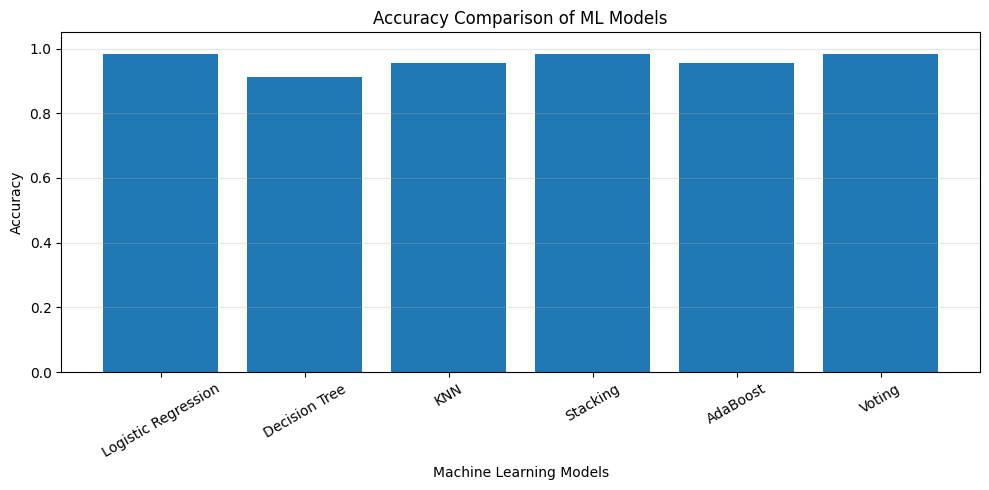

In [24]:

# Accuracy Comparison Graph

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


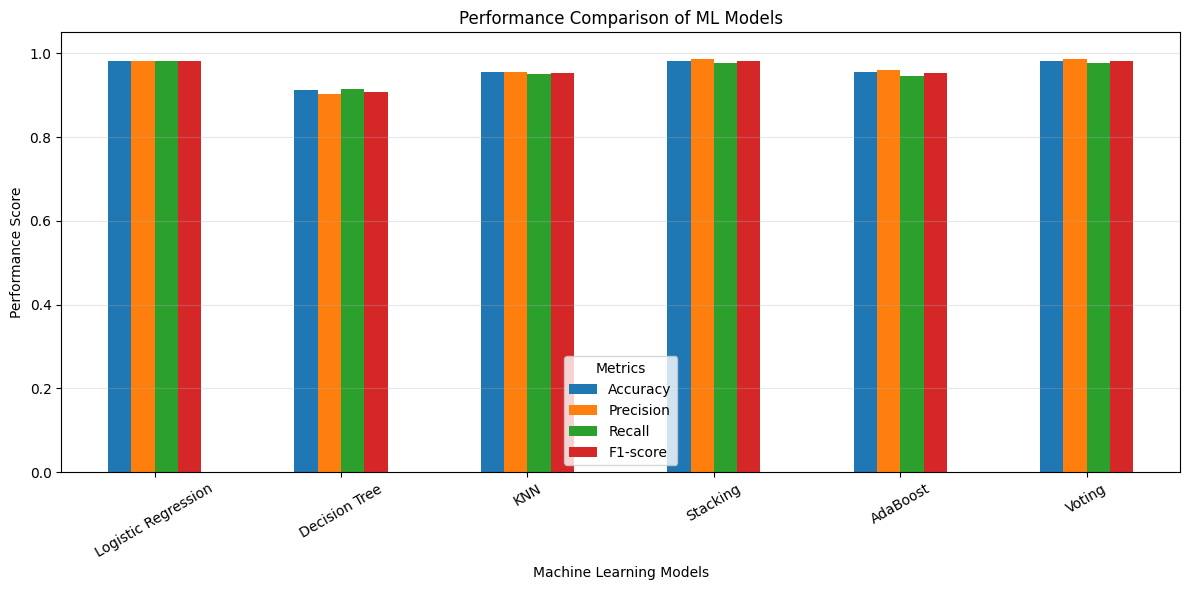

In [25]:

# Compare Accuracy, Precision, Recall and F1-score

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")

plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [26]:

# Find the best model based on F1-score

best_model = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-score:", round(best_model["F1-score"], 4))


Best Model: Logistic Regression
Accuracy: 0.9825
Precision: 0.9812
Recall: 0.9812
F1-score: 0.9812


In [27]:

# Compare only Ensemble Models

ensemble_results = results_df[
    results_df["Model"].isin([
        "Stacking",
        "AdaBoost",
        "Voting"
    ])
]

print("Ensemble Learning Comparison:")
display(ensemble_results.round(4))

# Best Ensemble Model
best_ensemble = ensemble_results.loc[
    ensemble_results["F1-score"].idxmax()
]

print("\nBest Ensemble Model:", best_ensemble["Model"])
print("F1-score:", round(best_ensemble["F1-score"], 4))


Ensemble Learning Comparison:


,Model,Accuracy,Precision,Recall,F1-score
3,Stacking,0.9825,0.9865,0.9762,0.9810
4,AdaBoost,0.9561,0.9605,0.9454,0.9521
5,Voting,0.9825,0.9865,0.9762,0.9810



Best Ensemble Model: Stacking
F1-score: 0.981


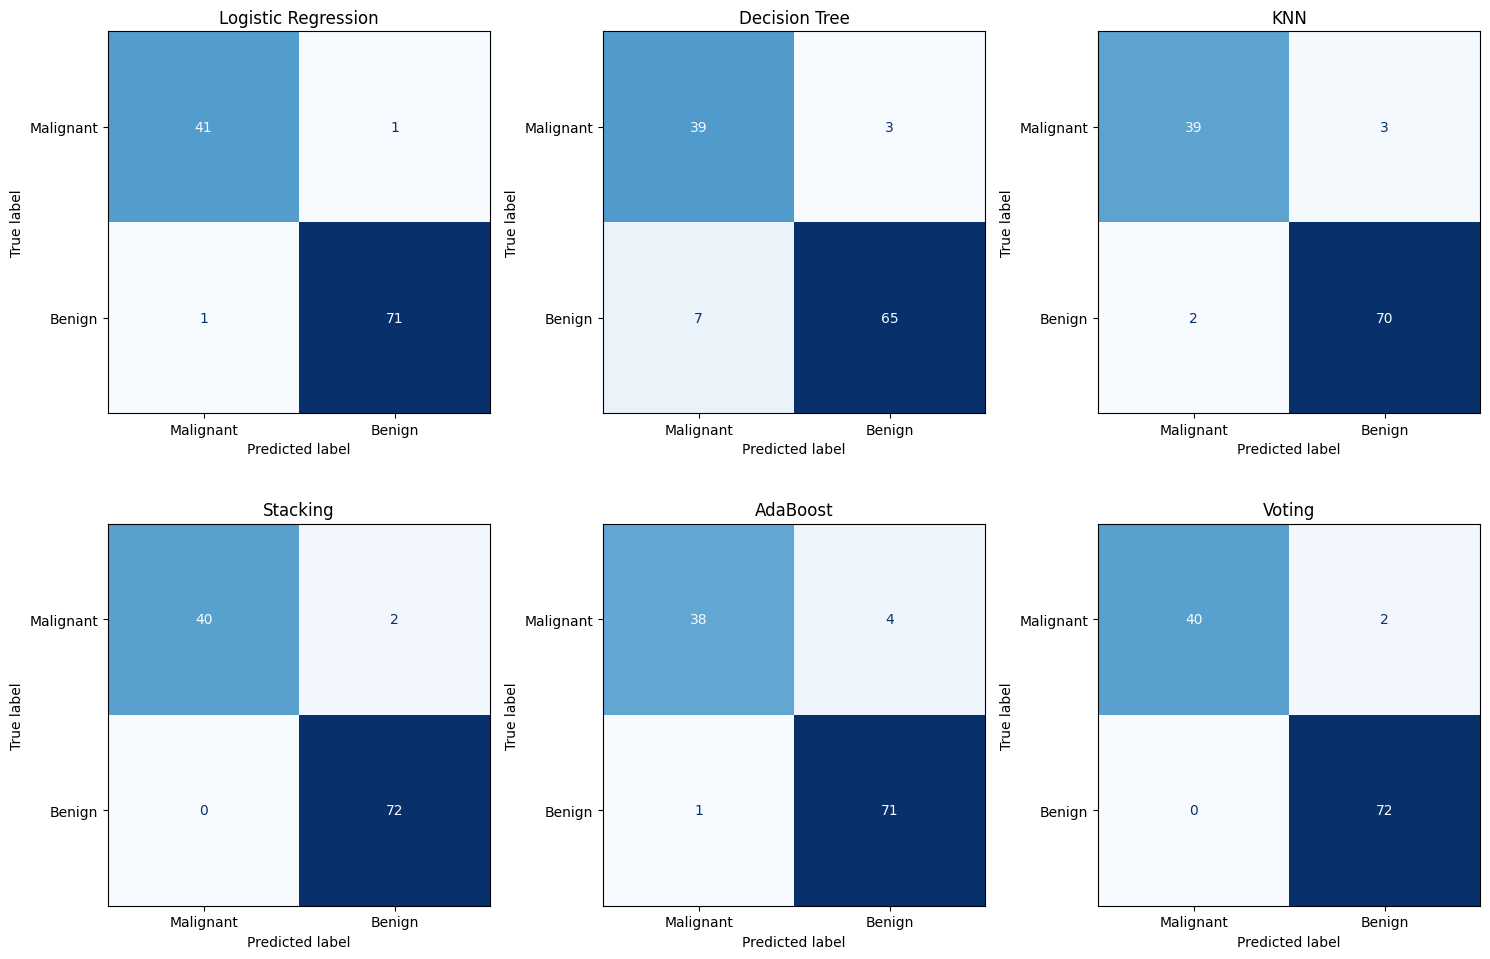

In [28]:

# Import required library
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, (model_name, predictions) in zip(
    axes.flatten(),
    model_predictions.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Malignant", "Benign"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()


In [29]:

# Count incorrect predictions for each model

print("Incorrect Predictions Comparison:\n")

for model_name, predictions in model_predictions.items():

    incorrect = (y_test != predictions).sum()

    print(model_name, ":", incorrect, "incorrect predictions")


Incorrect Predictions Comparison:

Logistic Regression : 2 incorrect predictions
Decision Tree : 10 incorrect predictions
KNN : 5 incorrect predictions
Stacking : 2 incorrect predictions
AdaBoost : 5 incorrect predictions
Voting : 2 incorrect predictions


In [30]:

# Compare missed malignant cases

print("Missed Malignant Cases:\n")

for model_name, predictions in model_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    missed_malignant = cm[0, 1]

    print(model_name, ":", missed_malignant)


Missed Malignant Cases:

Logistic Regression : 1
Decision Tree : 3
KNN : 3
Stacking : 2
AdaBoost : 4
Voting : 2


In [31]:

# Save performance comparison as CSV

results_df.to_csv(
    "ensemble_model_comparison.csv",
    index=False
)

print("Performance comparison saved successfully!")


Performance comparison saved successfully!


In [32]:

# Display final performance comparison

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 50)

display(results_df.round(4))

print("\nBest Overall Model:")
display(results_df.loc[[results_df["F1-score"].idxmax()]])

print("\nBest Ensemble Model:")
display(ensemble_results.loc[[ensemble_results["F1-score"].idxmax()]])


FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9825,0.9812,0.9812,0.9812
1,Decision Tree,0.9123,0.9019,0.9157,0.9075
2,KNN,0.9561,0.9551,0.9504,0.9526
3,Stacking,0.9825,0.9865,0.9762,0.9810
4,AdaBoost,0.9561,0.9605,0.9454,0.9521
5,Voting,0.9825,0.9865,0.9762,0.9810



Best Overall Model:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.982456,0.981151,0.981151,0.981151



Best Ensemble Model:


,Model,Accuracy,Precision,Recall,F1-score
3,Stacking,0.982456,0.986486,0.97619,0.980956
